### Imports

In [1]:
import os, sys
import numpy as np
import yaml
from tqdm import tqdm
from PIL import Image

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_directory, read_h5

from eval_segmentation import write_seg_metrics_csv, write_avg_metrics_yaml_from_csv, percentage_hint_on_mask




2024-09-18 07:49:17.479007: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-18 07:49:17.492689: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-18 07:49:17.496831: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-18 07:49:17.509207: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-09-18 07:49:18.660114: W tensorflow/compiler/tf2

### Datasets

In [2]:
# Load the YAML file into a dictionary
dataset_yaml_file = '/workspace/home/data/datasets.yaml'
with open(dataset_yaml_file, 'r') as file:
    datasets = yaml.safe_load(file)

#datasets

## Evaluate data
### Load data


In [16]:
# get dataset
dataset_key = "ISIC2019"#'Pascal_VOC07' #
dataset = datasets[dataset_key]
id_tag = '0004'

# load the ground truth, predicted segmentations and images
segmentation_path = f"/workspace/home/data/{datasets[dataset_key]['dataset_dir']}/seg_dito/0004"
#segmentation_path = f"/workspace/home/data/{datasets[dataset_key]['dataset_dir']}/seg_groundedRMBG-1.4/{id_tag}"
segmentation_gt_path = datasets[dataset_key]['gt_seg_path']

segmentation_masks_confounder = get_images_from_directory(dir_path=segmentation_path) # might be wrong: filter with label
segmentation_masks_gt = get_images_from_directory(dir_path=segmentation_gt_path)

In [17]:
segmentation_masks_hint_path = "/workspace/datasets/ISIC19/cancer_masks_hint.h5"
segmentation_masks_hint_path2 = "/workspace/datasets/ISIC19/not_cancer_masks_hint.h5"
segmentation_masks_hint = read_h5(segmentation_masks_hint_path)
segmentation_masks_hint2 = read_h5(segmentation_masks_hint_path2)

print(segmentation_masks_hint["cancer_masks_hint"].shape)
print(segmentation_masks_hint2["not_cancer_masks_hint"].shape)

# Problem: how do I know what mask corresponds to what image?

(2553, 1, 299, 299)
(19734, 1, 299, 299)


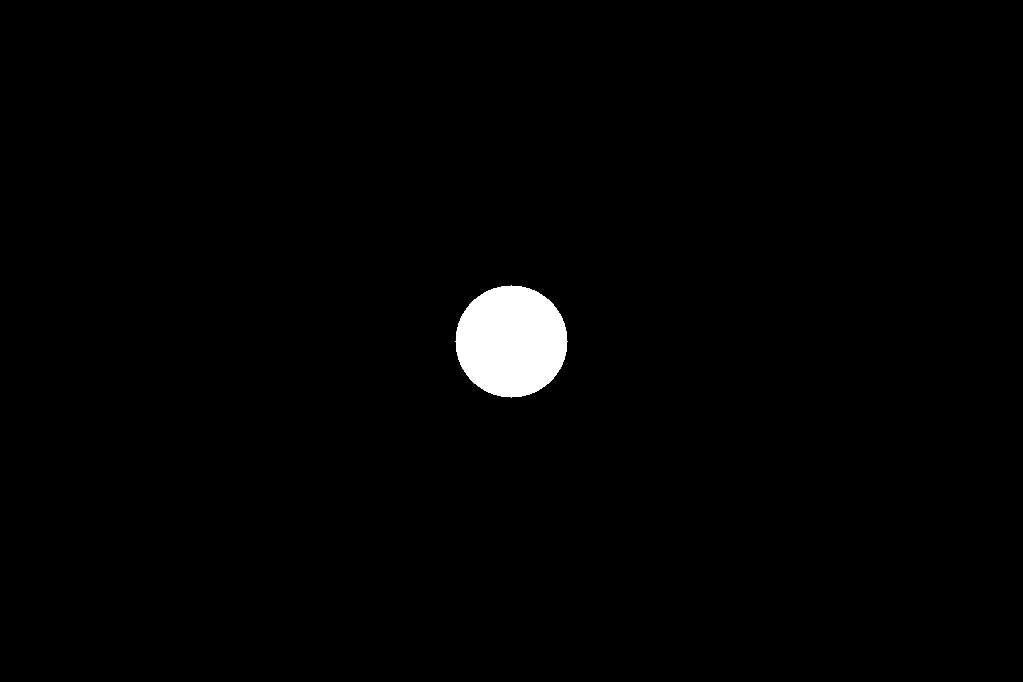

In [18]:
# create hint masks (segmentation mask with circle in the center)
def create_hint_mask(image_shape):
    hint_mask = np.zeros(image_shape[:2], dtype=np.uint8)
    center = (image_shape[1] // 2, image_shape[0] // 2)
    radius = min(image_shape[0], image_shape[1]) // 12  # Adjust the radius as needed
    y, x = np.ogrid[:image_shape[0], :image_shape[1]]
    mask = (x - center[0]) ** 2 + (y - center[1]) ** 2 <= radius ** 2
    hint_mask[mask] = 1
    return hint_mask

# get size of image
image_shape = Image.open(segmentation_masks_confounder[0]["file_path"]).size
image_shape_np = (image_shape[1], image_shape[0])  # (height, width)

hint_mask = create_hint_mask(image_shape_np)

pil_hint_mask = Image.fromarray(hint_mask * 255).convert("L")
pil_hint_mask.show()


### Calculate metrics

In [19]:
# create csv path
base_dir = f"/workspace/home/pipeline_outputs/{datasets[dataset_key]['dataset_dir']}/{id_tag}"
os.makedirs(base_dir, exist_ok=True)
csv_path = os.path.join(base_dir, 'seg_metrics.csv')

# create csv file
dilation_kernel_size = 5
dilation_iterations = 4
dilation_function_params = {'kernel_size': dilation_kernel_size, 'iterations': dilation_iterations}
#write_seg_metrics_csv(csv_path, segmentation_masks_confounder, segmentation_masks_gt, hint_mask, dilation_function_params)

# create yaml file
yaml_path = os.path.join(base_dir, 'seg_metrics_avg.yaml')
write_avg_metrics_yaml_from_csv(csv_path, yaml_path)



FileNotFoundError: [Errno 2] No such file or directory: '/workspace/home/pipeline_outputs/ISIC2019/0004/seg_metrics.csv'